# Immobilier et performance énergétique en France

Projet du cours Python pour la data science, ENSAE Paris.
Marc Olivier Bouiti Banza, Karlane Vasthi Foudjin Sipeuwo, Aniela Nomwendé Tania Zoungrana.

Ce notebook est le rapport du projet. Il s'exécute du début à la fin à partir des fichiers produits par la chaîne de traitement (voir le README).

In [13]:
import importlib
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
chargement = importlib.import_module("src.chargement")

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update(
    {
        "figure.figsize": (9, 4.5),
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

ORDRE = chargement.ETIQUETTES
COULEURS = {
    "A": "#009C6D",
    "B": "#52B153",
    "C": "#78BD76",
    "D": "#F4E70F",
    "E": "#F0B40F",
    "F": "#EB8235",
    "G": "#D7221F",
}

## Introduction

Au moment d'acheter un logement, les dépenses d'énergie et les travaux à prévoir peuvent compter dans le choix du bien et dans le prix que l'acquéreur est prêt à payer. Le diagnostic de performance énergétique (DPE) lui donne un repère en classant les logements de A à G selon leur consommation conventionnelle d'énergie et leurs émissions de gaz à effet de serre. Les classes F et G correspondent aux logements les moins performants, couramment appelés « passoires énergétiques ». Si cette information entre dans les décisions d'achat, elle peut aussi se retrouver dans les prix de vente.

Pour les biens destinés à la location, le classement énergétique a également des conséquences réglementaires. Le DPE, réformé et devenu opposable en juillet 2021, sert de référence aux mesures prévues par la loi Climat et résilience. En métropole, le gel des loyers des logements F et G du parc privé s'applique depuis août 2022 aux baux concernés. Depuis janvier 2025, les logements G ne remplissent plus le critère de décence énergétique exigé pour les nouveaux baux d'habitation, les renouvellements et les reconductions tacites (Ministère chargé du logement, 2025a, 2025b). Ces contraintes peuvent amener les acquéreurs à anticiper des travaux ou des revenus locatifs différents. La période 2022–2025 permet ainsi d'étudier les écarts de prix alors que ces mesures entrent progressivement en application.

Une comparaison entre étiquettes ne suffit pourtant pas à comprendre ces écarts. Les logements les mieux classés peuvent aussi être plus récents, plus grands ou situés dans des communes plus chères. Sur les ventes françaises de 2016 à 2021, Chareyron (2026) observe que les logements mieux classés se vendent plus cher, après prise en compte de plusieurs caractéristiques des biens. Notre projet reprend cette question sur une période plus récente : les logements mieux classés se vendent-ils plus cher au m² lorsque l'on compare des biens semblables, et ces écarts ont-ils évolué entre 2022 et 2025, notamment pour les classes F et G ?

Nous rapprochons pour cela les ventes enregistrées dans les Demandes de valeurs foncières (DVF) de la DGFiP et les diagnostics des logements existants diffusés par l'ADEME depuis juillet 2021. Ce rapprochement permet d'associer un prix de vente à une étiquette énergétique. Après nettoyage, appariement et retrait des ventes rapprochées, nous disposons de 1 568 214 ventes de maisons et d'appartements dans 93 départements métropolitains. Nous décrivons d'abord les biens vendus et les écarts bruts de prix au m², puis nous comparons les ventes au sein de groupes définis par la commune, le type de bien, la tranche de surface, la période de construction et le trimestre de vente. L'évolution de ces écarts est ensuite examinée année par année.

La démarche reste descriptive : même au sein de ces groupes, certaines caractéristiques des logements ne sont pas observées et l'appariement peut comporter des erreurs. Une évolution des écarts de prix ne pourra donc pas être attribuée à elle seule aux changements réglementaires. Le rapport présente d'abord la construction des données et de l'échantillon, puis les résultats des comparaisons. Il se termine par une vérification fondée sur un appariement plus strict et par une discussion des limites de l'analyse.

## Partie 1. Les données

### 1.1 Sources et traitement

*À rédiger.* Les trois sources, la chaîne de traitement et les six règles d'appariement (détail en annexe A).

![Chaîne de traitement](../docs/chaine_de_traitement.png)

In [14]:
ventes = chargement.charger_ventes()
echantillon = chargement.echantillon_analyse(ventes)
print(f"{len(ventes):,} ventes ; {ventes['apparie'].sum():,} appariées ; "
      f"{len(echantillon):,} dans l'échantillon d'analyse")

3,202,384 ventes ; 1,571,690 appariées ; 1,568,214 dans l'échantillon d'analyse


### 1.2 Le marché

Prix médian au m² de toutes les ventes, appariées ou non, par trimestre et par département.

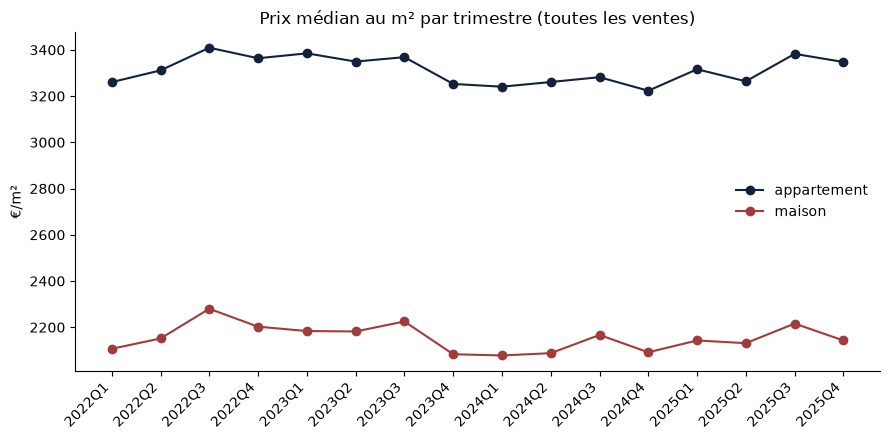

In [15]:
prix_trimestre = (ventes.groupby(["trimestre", "type_bien"], observed=True)["prix_m2"]
                  .median()
                  .unstack())

ax = prix_trimestre.plot(marker="o", color={"appartement": "#14213D", "maison": "#A23B3B"})
ax.set_xticks(range(len(prix_trimestre)), prix_trimestre.index, rotation=45, ha="right")
ax.set(title="Prix médian au m² par trimestre (toutes les ventes)", xlabel="", ylabel="€/m²")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

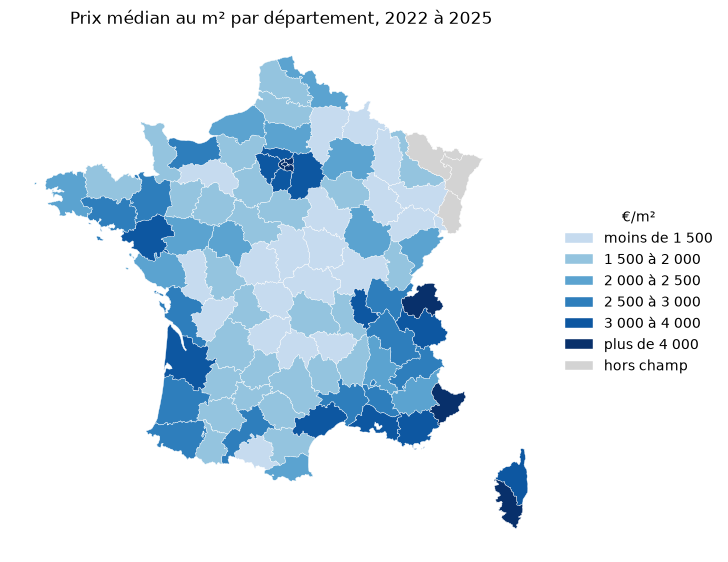

In [16]:
# Contours des départements (projet france-geojson de Grégoire David)
URL_DEPARTEMENTS = (
    "https://raw.githubusercontent.com/gregoiredavid/france-geojson/"
    "master/departements-version-simplifiee.geojson"
)
departements = gpd.read_file(URL_DEPARTEMENTS)

prix_dep = (
    ventes.groupby("code_departement", observed=True)["prix_m2"]
    .median()
    .reset_index()
)
prix_dep["code_departement"] = prix_dep["code_departement"].astype(str)
carte = departements.merge(
    prix_dep, left_on="code", right_on="code_departement", how="left"
)

# Classes de prix : Paris ne doit pas écraser les autres couleurs.
CLASSES = [0, 1500, 2000, 2500, 3000, 4000, 20000]
NOMS = [
    "moins de 1 500",
    "1 500 à 2 000",
    "2 000 à 2 500",
    "2 500 à 3 000",
    "3 000 à 4 000",
    "plus de 4 000",
]
carte["classe_prix"] = pd.cut(carte["prix_m2"], CLASSES, labels=NOMS)

bleus = ListedColormap(plt.cm.Blues(np.linspace(0.25, 1, len(NOMS))))
fig, ax = plt.subplots(figsize=(7, 7))
carte.plot(
    column="classe_prix",
    cmap=bleus,
    categorical=True,
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.3,
    missing_kwds={"color": "lightgrey", "label": "hors champ"},
    legend_kwds={
        "title": "€/m²",
        "loc": "center left",
        "bbox_to_anchor": (1, 0.5),
        "frameon": False,
    },
)
ax.set_title("Prix médian au m² par département, 2022 à 2025")
ax.set_axis_off()
plt.show()

En gris : la Moselle, le Bas-Rhin et le Haut-Rhin, absents de la base des ventes (régime du livre foncier).

*À rédiger.* Commentaire des deux graphiques.

### 1.3 L'échantillon

Part des ventes auxquelles un DPE a été rattaché, puis comparaison des ventes appariées et non appariées. Le détail par département est en annexe B.

In [17]:
taux = (ventes.groupby(["annee", "type_bien"], observed=True)["apparie"]
        .mean()
        .mul(100)
        .unstack())
taux["ensemble"] = ventes.groupby("annee")["apparie"].mean() * 100
taux.round(1)

type_bien,appartement,maison,ensemble
annee,,,
2022,43.00,31.20,36.40
2023,61.00,42.40,50.70
2024,67.60,46.40,55.50
2025,70.30,47.50,57.40


In [18]:
statut = ventes["apparie"].map({True: "appariées", False: "non appariées"})

comparaison = (ventes.groupby(["annee", statut], observed=True)
               .agg(ventes=("prix_m2", "size"),
                    prix_m2_median=("prix_m2", "median"),
                    surface_mediane=("surface", "median"),
                    part_maisons=("type_bien", lambda x: (x == "maison").mean() * 100))
               .round(1))
comparaison.index.names = ["année", "statut"]
comparaison

ventes  prix_m2_median  surface_mediane  part_maisons
année statut                                                              
2022  appariées      350889         2826.60            73.40         48.30
      non appariées  613477         2500.00            79.00         60.80
2023  appariées      385772         2837.80            72.00         46.70
      non appariées  375424         2381.20            79.10         65.00
2024  appariées      384404         2732.90            73.00         47.50
      non appariées  307711         2258.50            80.00         68.60
2025  appariées      450625         2810.70            73.10         46.60
      non appariées  334082         2297.10            82.00         69.50

*À rédiger.* Commentaire : évolution du taux d'appariement et différences entre ventes appariées et non appariées.

## Partie 2. Les résultats

Toutes les analyses de cette partie portent sur l'échantillon d'analyse : les ventes appariées, sans les ventes rapprochées.

### 2.1 Description par étiquette

L'analyse porte sur 1 568 214 ventes réalisées entre 2022 et 2025 dans 93 départements métropolitains. Nous retenons les ventes appariées à un DPE, après exclusion des ventes rapprochées. Dans les sections 2.1 et 2.2, le prix étudié est toujours le prix de vente au m², exprimé en €/m² ; la surface est exprimée en m². Les résultats décrivent les biens vendus dans cet échantillon et ne peuvent pas être directement étendus à l'ensemble du parc de logements.

**Caractéristiques des biens vendus**

| DPE | Nombre de ventes | Prix moyen (€/m²) | Prix médian (€/m²) | Surface médiane (m²) | Maisons (%) | Construction avant 1975 (%) | Construction ≥ 2013 (%) |
| :-- | --: | --: | --: | --: | --: | --: | --: |
| A | 27 836 | 3 559,76 | 3 203,79 | 104,00 | 83,1 | 6,8 | 77,9 |
| B | 69 933 | 3 563,12 | 3 208,69 | 86,35 | 54,2 | 21,3 | 25,7 |
| C | 462 860 | 3 484,66 | 3 076,92 | 70,94 | 38,8 | 29,9 | 10,0 |
| D | 505 964 | 3 364,08 | 2 684,76 | 75,00 | 45,4 | 61,0 | 0,6 |
| E | 305 375 | 3 536,57 | 2 538,89 | 70,18 | 48,6 | 83,1 | < 0,1 |
| F | 123 211 | 3 378,71 | 2 319,29 | 70,94 | 59,7 | 93,3 | < 0,1 |
| G | 73 035 | 3 498,36 | 2 346,94 | 65,82 | 65,4 | 97,2 | < 0,1 |

*Lecture : les pourcentages sont calculés au sein de chaque étiquette. Les deux dernières colonnes reposent sur les périodes de construction déclarées : « avant 1948 » et « 1948-1974 » pour la première ; « 2013-2021 » et « après 2021 » pour la seconde. La mention « < 0,1 » désigne une part positive inférieure à 0,1 %. Sources : `../reports/tables/description_dpe_france.csv` et `../reports/tables/construction_dpe_france.csv`. Les arrondis concernent uniquement la présentation.*

Les classes C et D regroupent à elles seules 61,8 % des ventes. Derrière cette répartition, les biens vendus présentent des profils assez différents : les maisons représentent 83,1 % des ventes en A, contre 38,8 % en C. La surface médiane atteint 104 m² en A, contre 65,82 m² en G. Les écarts de prix au m² entre étiquettes s'observent donc entre des groupes dont la composition diffère.

Le contraste apparaît aussi dans les périodes de construction. Parmi les ventes classées A, 77,9 % concernent des biens construits à partir de 2013, d'après la période déclarée. À l'autre extrémité, les constructions antérieures à 1975 représentent 93,3 % des ventes en F et 97,2 % en G. Plus de la moitié des biens vendus en G, soit 54,7 %, datent même d'avant 1948. La répartition détaillée par période est disponible dans le tableau CSV associé. Ces informations restent distinctes de l'année précise de construction, qui n'est pas toujours exploitable pour les corrélations.

**Répartition géographique des ventes de logements F ou G**

![Part des ventes de logements F ou G par département](../reports/figures/carte_part_fg_france_noms.png)

La carte rapporte, pour chaque département, le nombre de ventes retenues de logements F ou G au nombre total de ventes retenues. Sur l'ensemble de l'échantillon, ces deux classes représentent 196 246 ventes sur 1 568 214, soit 12,51 %. Cette proportion est calculée à partir des effectifs totaux, sans faire la moyenne simple des pourcentages départementaux.

Les différences géographiques sont marquées. La part F/G atteint 40,04 % dans la Creuse (645 ventes sur 1 611), 30,64 % dans le Cantal (790 sur 2 578) et 28,26 % dans la Nièvre (1 255 sur 4 441). Elle est plus faible dans l'Aude, à 2,01 % (213 sur 10 614), en Haute-Corse, à 2,47 % (30 sur 1 216), et dans l'Hérault, à 2,56 % (1 151 sur 44 989).

La Moselle, le Bas-Rhin et le Haut-Rhin apparaissent en gris car aucune vente de l'échantillon n'y est observée. Il ne faut donc pas lire cette couleur comme une absence de logements F ou G. Les territoires ultramarins ne sont pas représentés sur cette carte métropolitaine. Enfin, les écarts entre départements portent sur les ventes retenues : ils peuvent refléter les caractéristiques des biens vendus et la sélection liée à l'appariement, sans que la carte permette de distinguer ces explications.

*Sources : données DVF–DPE préparées du projet ; fond départemental Etalab, millésime 2025, généralisation 100 m, projection Lambert-93. Calculs et effectifs : `../reports/tables/carte_part_fg_france.csv`.*

**Corrélations de Spearman**

![Corrélations de Spearman et effectifs par paire](../reports/figures/correlations_spearman_france.png)

La matrice met en relation le prix au m², la surface, la consommation conventionnelle d'énergie primaire par m² et par an, le rang DPE et l'année de construction. L'étiquette est codée de 1 pour A à 7 pour G : plus le rang est élevé, moins le classement énergétique est favorable.

La consommation et le rang DPE sont fortement associés, avec une corrélation de 0,921. L'année de construction est, quant à elle, négativement corrélée à la consommation (−0,568) et au rang DPE (−0,563). Parmi les observations disposant d'une année exploitable, les logements plus récents tendent ainsi à être moins consommateurs et mieux classés.

Les liens avec le prix au m² sont moins prononcés. Sa corrélation est de −0,132 avec le rang DPE et de −0,095 avec la consommation. Elle atteint −0,284 avec la surface et +0,165 avec l'année de construction. Ces coefficients décrivent des associations entre les rangs des observations ; ils ne s'interprètent ni comme des variations de prix en pourcentage, ni comme des effets causaux.

Les effectifs varient selon les variables disponibles. Les corrélations entre prix au m², surface et rang DPE reposent sur 1 568 214 ventes, contre 1 568 087 lorsque la consommation intervient. Chaque calcul utilise uniquement les ventes renseignées pour les deux variables concernées.

Pour l'année de construction, 598 081 valeurs sont absentes ou non numériques et 32 535 années renseignées sont écartées après vérification. Une année est retenue si elle est entière, positive, non postérieure à la vente et compatible avec la période de construction déclarée. Il reste 937 598 années exploitables, dont 937 496 avec une consommation renseignée. Aucune année n'est imputée. Les ventes concernées restent utilisées pour les autres corrélations lorsque leurs données le permettent. Les résultats faisant intervenir l'année doivent donc être lus en gardant à l'esprit qu'ils portent sur un sous-échantillon.

*Sources : `../reports/tables/correlations_spearman_france.csv`, `../reports/tables/effectifs_correlations_france.csv` et `../reports/tables/controle_annee_construction_france.csv`.*

### 2.2 Comparaison sans correction

Pour examiner les écarts de prix au m² entre étiquettes, nous distinguons les maisons des appartements. Les boîtes à moustaches présentent les distributions de chaque groupe sur une même échelle verticale, ce qui permet de comparer à la fois leurs médianes et leur dispersion.

![Prix au m² selon le DPE, appartements et maisons séparés](../reports/figures/boxplots_dpe_france.png)

Chaque boîte contient les 50 % centraux des prix au m², et le trait intérieur indique la médiane. Les moustaches s'étendent jusqu'aux valeurs observées dans la limite de 1,5 fois l'écart interquartile en dessous du premier quartile et au-dessus du troisième. Les points situés au-delà sont masqués pour faciliter la lecture, mais toutes les valeurs renseignées restent incluses dans les calculs.

| DPE | Prix médian des appartements (€/m²) | Prix médian des maisons (€/m²) |
| :-- | --: | --: |
| A | 4 169,63 | 3 055,68 |
| B | 3 716,41 | 2 845,36 |
| C | 3 427,36 | 2 622,47 |
| D | 3 125,28 | 2 313,73 |
| E | 3 394,68 | 2 010,87 |
| F | 3 869,23 | 1 810,34 |
| G | 4 998,09 | 1 760,00 |

*Source : `../reports/tables/description_type_dpe_france.csv`. Les effectifs de chaque groupe sont indiqués sur le graphique.*

Pour les maisons, le prix médian au m² diminue à mesure que l'on passe de A à G : il va de 3 055,68 à 1 760,00 €/m². La médiane en G est ainsi inférieure de 42,4 % à celle de A. Les distributions se recouvrent néanmoins largement : l'étiquette seule ne suffit pas à caractériser le prix au m² d'une vente.

Le profil des appartements est différent. Leur prix médian au m² baisse de A à D, puis remonte de E à G. Il atteint 4 998,09 €/m² en G, soit 19,9 % de plus qu'en A. Cette comparaison concerne toutefois des biens de tailles différentes : la surface médiane des appartements G est d'environ 34,2 m², contre 61,2 m² en A. La hausse observée pour les classes les moins favorables ne permet donc pas de conclure qu'un mauvais DPE augmenterait le prix d'un appartement.

Les deux écarts entre G et A sont calculés à partir des médianes non arrondies, selon la formule `100 × (médiane G / médiane A − 1)`, séparément pour chaque type de bien. Ils restent des écarts bruts entre groupes. Même après avoir séparé maisons et appartements, des différences de localisation, de surface, de période de construction et de date de vente subsistent. La section 2.3 prolonge cette analyse en comparant des logements semblables.

**Traçabilité des résultats**

Les tableaux et figures proviennent des sorties de `notebooks/karlane_description_france.ipynb`. Les CSV conservent la précision des calculs ; seuls les nombres présentés ici sont arrondis. Si les données ou les règles de sélection changent, il faudra régénérer ces sorties et actualiser le texte. La validation finale de la reproductibilité prévoit une exécution complète du notebook après redémarrage du noyau.

### 2.3 Résultat principal : à logement comparable

*À faire.* Écart de prix par étiquette dans des groupes de ventes semblables (commune, type, tranche de surface, période de construction, trimestre), par rapport à G et à D, avec intervalles de confiance. Diagramme en barres : écart sans correction et écart à logement comparable.

### 2.4 Évolution de 2022 à 2025

*À faire.* Le même calcul année par année ; courbe de l'écart des classes F et G avec les dates du gel des loyers et de l'interdiction de louer.

## Partie 3. Vérification et limites

### 3.1 Appariement strict

*À faire.* Le résultat de 2.3 refait sans les ventes ambiguës et sans les ventes appariées par la distance (`chargement.appariement_strict`).

### 3.2 Limites

*À rédiger.* Reprendre les limites de la note de projet.

## Conclusion

*À rédiger.*

## Annexes

### Annexe A. Règles d'appariement

*À rédiger.*

### Annexe B. Taux d'appariement

*À faire.* Tableau par année et type de bien, carte par département.

### Annexe C. Ventes appariées et non appariées

*À faire.* Comparaison détaillée, et répartition des étiquettes comparée à celle du parc de logements.

### Annexe D. Dictionnaire des variables

*À rédiger.*

## Références
- Ministère chargé du logement (2025a). [Diagnostic de performance énergétique – DPE](https://www.ecologie.gouv.fr/politiques-publiques/diagnostic-performance-energetique-dpe), page mise à jour le 19 décembre 2025.

- Ministère chargé du logement (2025b). [Location et gel des loyers des passoires énergétiques](https://www.ecologie.gouv.fr/politiques-publiques/location-gel-loyers-passoires-energetiques), page mise à jour le 19 décembre 2025.

- Chareyron, S. (2026). [The valuation of energy efficiency labels in the French housing market](https://journals.sagepub.com/doi/abs/10.1177/00420980251410866). *Urban Studies*. DOI : 10.1177/00420980251410866.

*À compléter à partir de la note de projet.*